# Task 2: SigLIP-Qwen VLM (Google Colab)

## Setup

In [1]:
import os
import subprocess
import sys

from google.colab import drive

drive.mount("/content/drive")
SAVE = "/content/drive/MyDrive/atml-pa3"
os.makedirs(SAVE + "/results", exist_ok=True)
os.makedirs(SAVE + "/ckpt", exist_ok=True)

REPO = "/content/atml-pa3"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "https://github.com/syeddaniyalg/atml-pa3", REPO], check=True)
os.chdir(REPO)
sys.path.insert(0, REPO)

# results and recovery checkpoints live on Drive so a disconnected runtime can resume;
# the large feature cache stays on the fast local disk and is rebuilt if lost
os.environ["PA3_RESULTS"] = SAVE + "/results"
os.environ["PA3_CKPT"] = SAVE + "/ckpt"
os.environ["PA3_CACHE"] = "/content/cache"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

Mounted at /content/drive


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], returncode=0)

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!df -h /content | tail -1

name, memory.total [MiB]
Tesla T4, 15360 MiB
overlay         113G  337M  113G   1% /


## Splits and SigLIP features

Feature extraction is resumable and cached on the local disk.

In [3]:
!python -m task2.run --mode prep

I0000 00:00:1794555638.341850    1136 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794555640.591219    1136 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
07:40:43 | task2-prep-196 | env: {'torch': '2.14.1+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
v2_Complementary_Pairs_Val_mscoco.zip: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 772608/772608 [00:00<00:00, 2093115.36B/s]
07:41:05 | task2-prep-196 | raw annotations ready in /content/cache/task2/raw
07:41:32 | task2-prep-196 | train pools: presence=1200 counting=1200
07:44:51 | task2-prep-196 | isolation

## Train and evaluate

Set `OPTIONAL = False` to skip the 49-token run.

In [4]:
OPTIONAL = False
!python -m task2.run --mode all --resume --gpus 0 {"--optional" if OPTIONAL else ""}

I0000 00:00:1794556258.179635    3966 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794556260.696408    3966 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
07:51:02 | task2-all-196 | env: {'torch': '2.14.1+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
07:51:02 | task2-all-196 | features cached: 9283 images
[vlm196|gpu0] start: -m task2.run --mode train --tokens 196 --resume
[vlm196|gpu0] WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
[vlm196|gpu0] I0000 00:00:1794556273.876957    4079 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[v

## Results

,condition,accuracy %,presence %,counting %,pair acc %,identical %,empty %,follows partner %,answer NLL,sec/answer
0,correct,"71.1 [62.5, 79.7]","93.8 [87.5, 98.4]","48.4 [35.9, 60.9]","56.2 [43.8, 67.2]","21.9 [12.5, 32.8]","0.0 [0.0, 0.0]","15.6 [9.4, 21.9]","0.849 [0.589, 1.148]",0.0384
1,complementary,"15.6 [9.4, 21.9]","6.2 [1.6, 12.5]","25.0 [15.6, 35.9]","3.1 [0.0, 7.8]","21.9 [12.5, 32.8]","0.0 [0.0, 0.0]","71.1 [62.5, 79.7]","3.876 [3.343, 4.430]",0.0395
2,mismatched,"35.2 [28.1, 42.2]","48.4 [40.6, 56.2]","21.9 [12.5, 31.2]","6.2 [1.6, 12.5]","59.4 [46.9, 71.9]","0.0 [0.0, 0.0]","39.1 [32.0, 46.1]","2.585 [2.247, 2.954]",0.0353
3,none,"32.8 [27.3, 38.3]","50.0 [50.0, 50.0]","15.6 [7.8, 23.4]","0.0 [0.0, 0.0]","100.0 [100.0, 100.0]","0.0 [0.0, 0.0]","32.8 [27.3, 38.3]","2.041 [1.797, 2.301]",0.0278


,condition,accuracy %,yes/no %,number %,other %,pair acc %,identical %,empty %,follows partner %,answer NLL,sec/answer
0,correct,"54.2 [48.1, 60.3]","59.2 [51.7, 66.8]","62.3 [49.8, 74.8]","43.8 [33.2, 54.7]","19.8 [12.5, 28.1]","56.2 [45.8, 65.6]","0.0 [0.0, 0.0]","27.1 [21.4, 32.8]","1.425 [1.176, 1.695]",0.0438
1,complementary,"30.2 [24.3, 36.1]","50.8 [42.6, 59.0]","12.3 [4.6, 21.2]","21.5 [13.3, 30.0]","3.1 [0.0, 7.3]","56.2 [45.8, 65.6]","0.0 [0.0, 0.0]","51.0 [44.8, 57.3]","2.439 [2.053, 2.846]",0.0406
2,mismatched,"32.7 [27.2, 38.5]","49.9 [43.2, 56.4]","31.9 [19.4, 44.4]","16.1 [8.6, 23.6]","4.2 [1.0, 8.3]","49.0 [39.6, 58.3]","0.0 [0.0, 0.0]","32.8 [27.1, 39.1]","2.245 [1.919, 2.583]",0.0415
3,none,"30.6 [25.2, 35.9]","48.6 [42.2, 54.4]","24.2 [13.7, 34.4]","16.9 [8.8, 26.1]","0.0 [0.0, 0.0]","100.0 [100.0, 100.0]","0.0 [0.0, 0.0]","28.1 [23.4, 32.8]","2.461 [2.124, 2.818]",0.0259


,suite,contrast,value
0,grounding,accuracy_correct_minus_complementary,"0.555 [0.414, 0.695]"
1,grounding,nll_complementary_minus_correct,"3.027 [2.371, 3.688]"
2,grounding,accuracy_correct_minus_mismatched,"0.359 [0.273, 0.445]"
3,grounding,nll_mismatched_minus_correct,"1.736 [1.318, 2.148]"
4,grounding,accuracy_correct_minus_none,"0.383 [0.312, 0.453]"
5,grounding,nll_none_minus_correct,"1.192 [0.900, 1.481]"
6,natural,accuracy_correct_minus_complementary,"0.240 [0.153, 0.329]"
7,natural,nll_complementary_minus_correct,"1.015 [0.675, 1.407]"
8,natural,accuracy_correct_minus_mismatched,"0.215 [0.135, 0.297]"
9,natural,nll_mismatched_minus_correct,"0.821 [0.490, 1.152]"


,tokens,stage,updates,train time (min),peak mem (GB),trainable connector,trainable LoRA,weights (MB)
0,196,caption,2250.0,44.97,1.89,1837056.0,0.0,7.0
1,196,vit,1500.0,33.26,1.95,1837056.0,4587520.0,24.6
2,196,natural,750.0,16.78,1.95,1837056.0,4587520.0,24.6
3,196,final eval,NaN,1.22,1.90,NaN,NaN,NaN
4,-,feature cache,NaN,5.60,0.43,NaN,NaN,2665.2


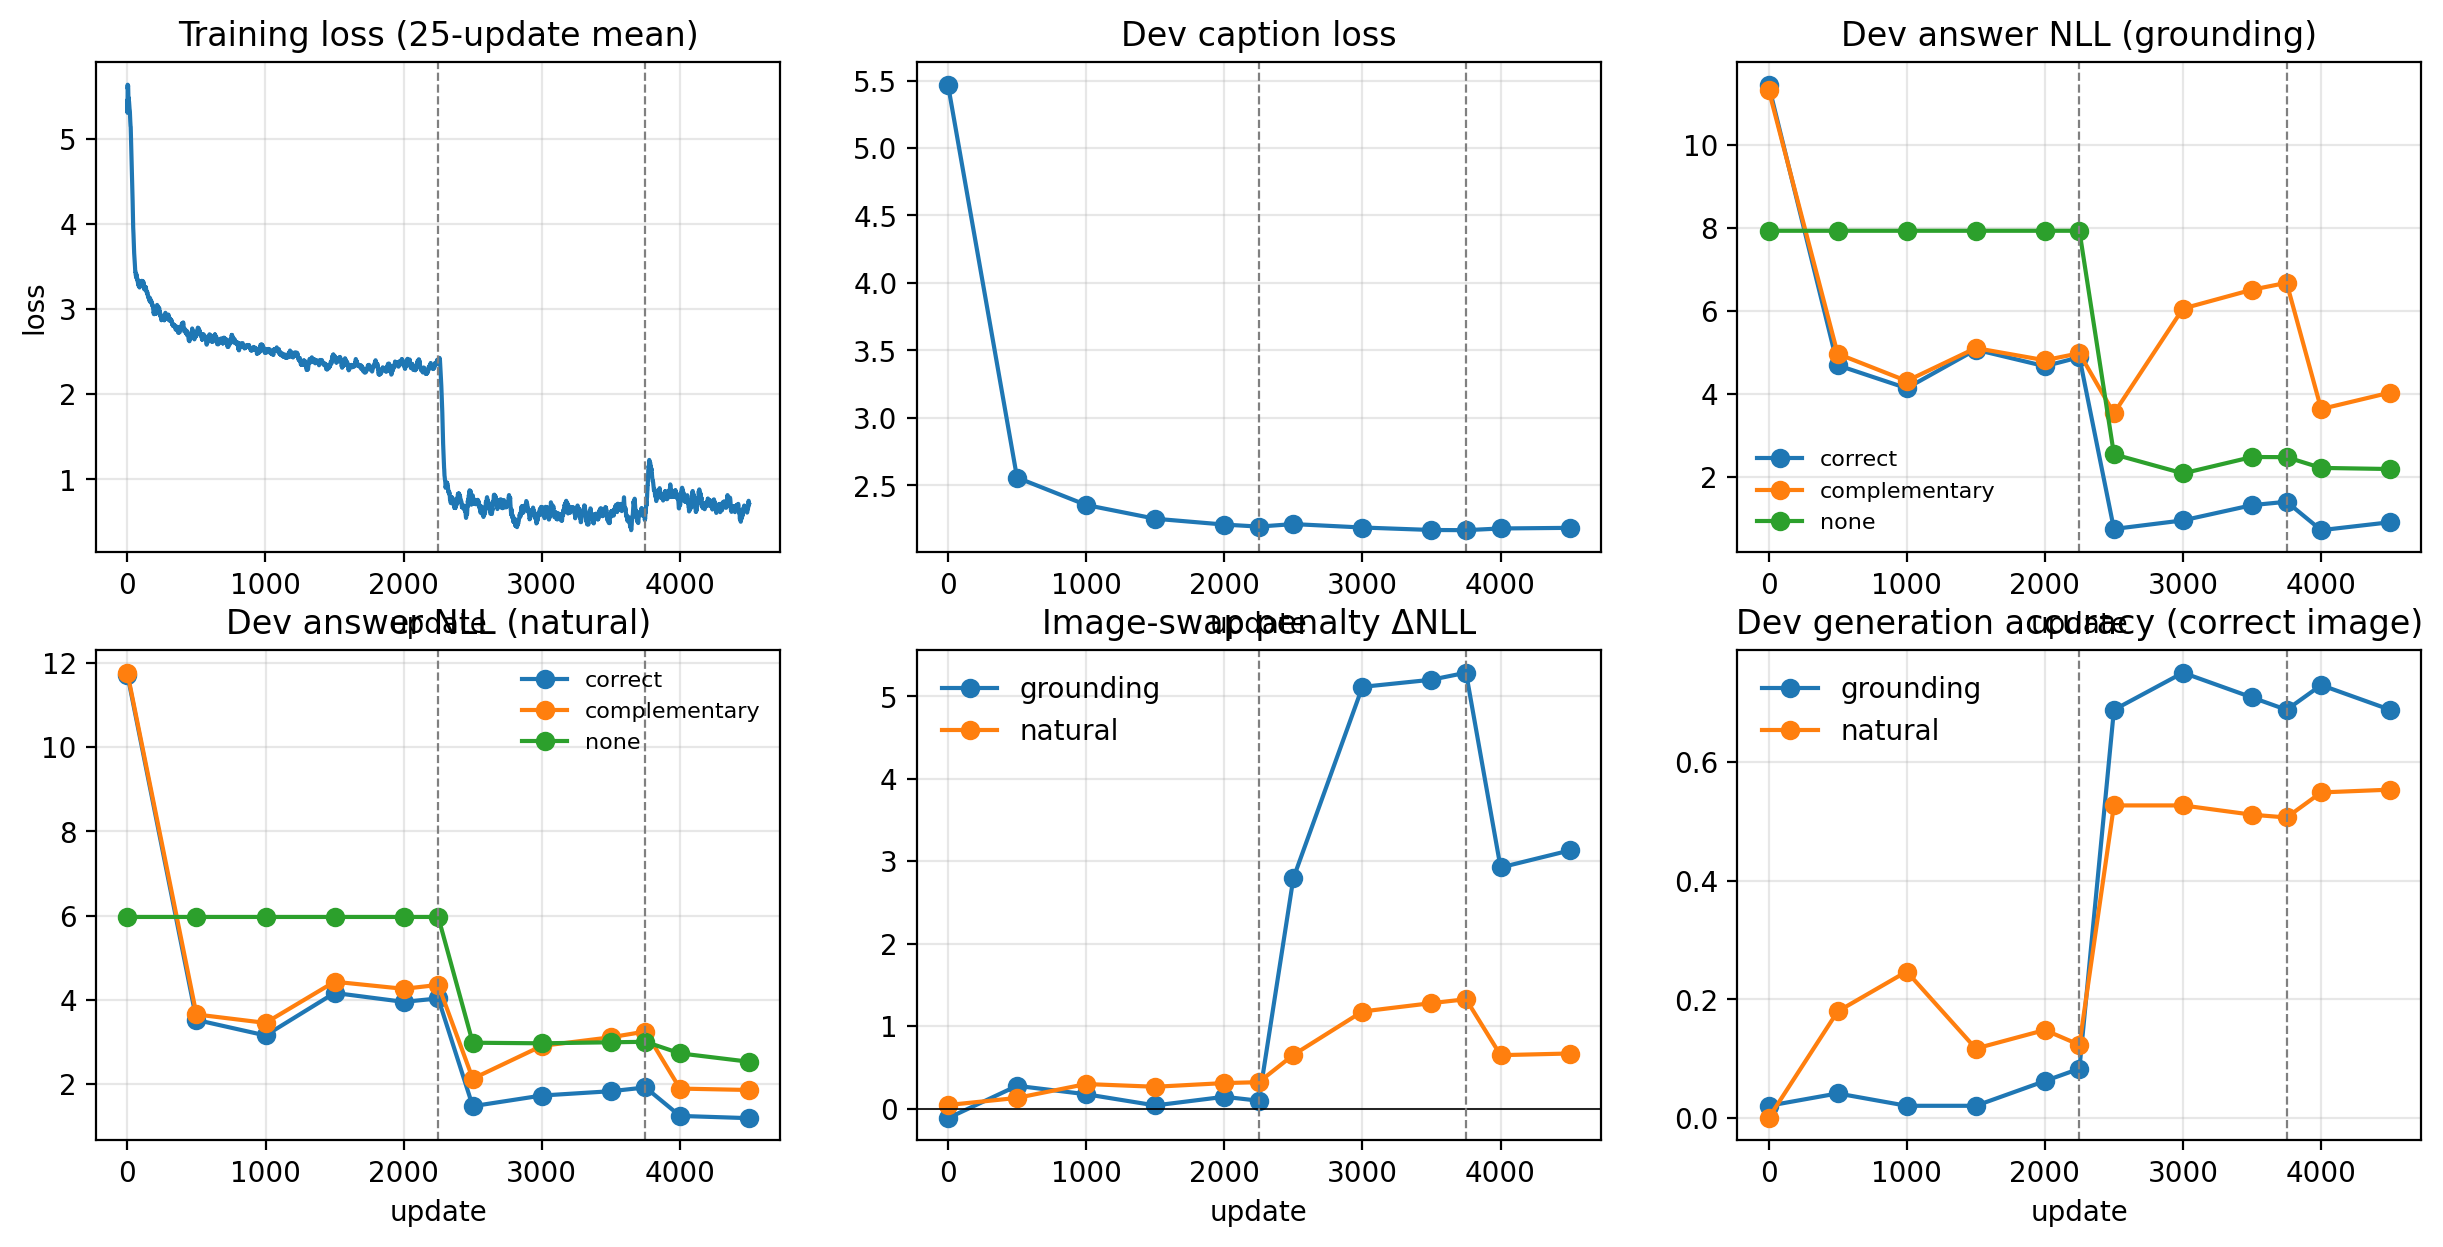

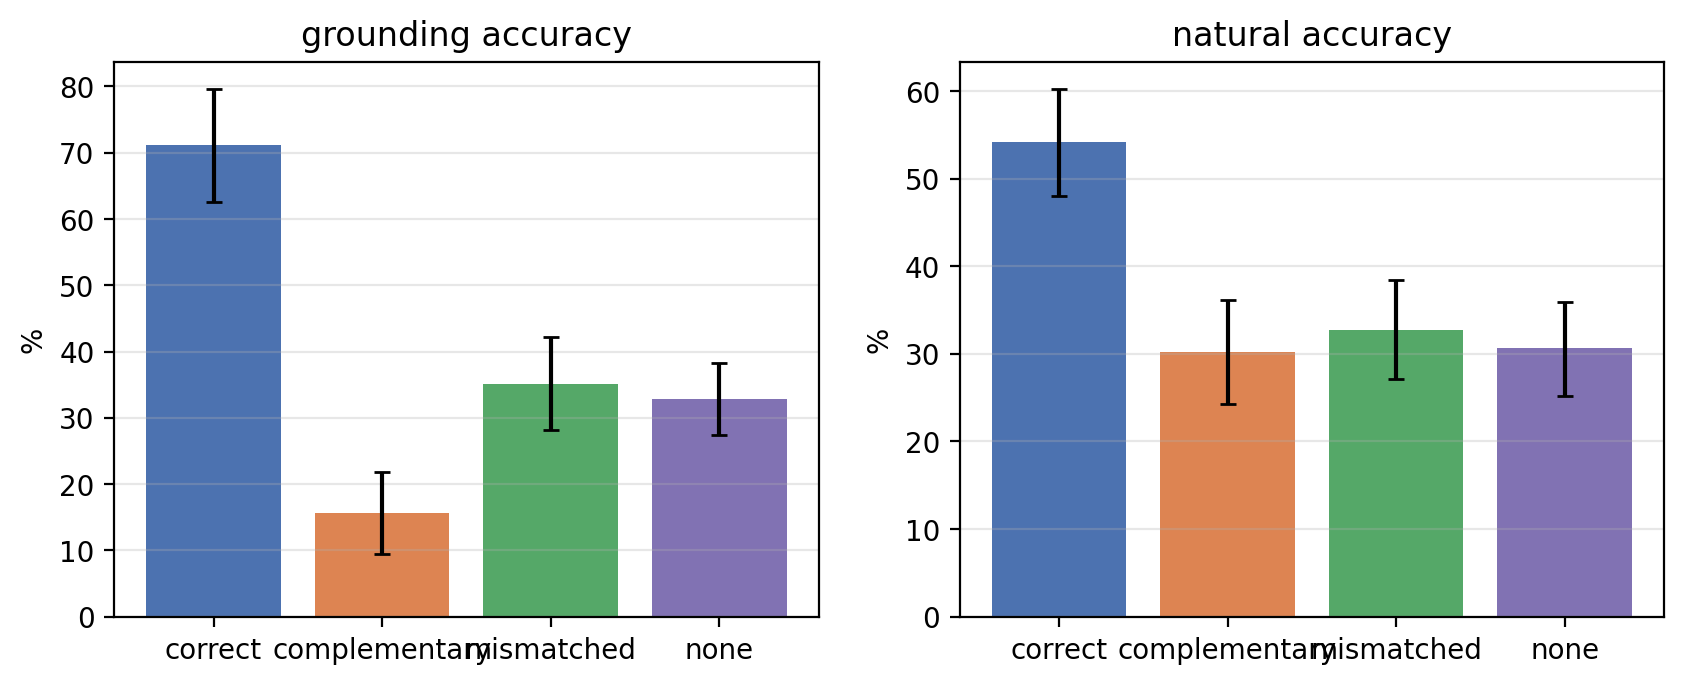

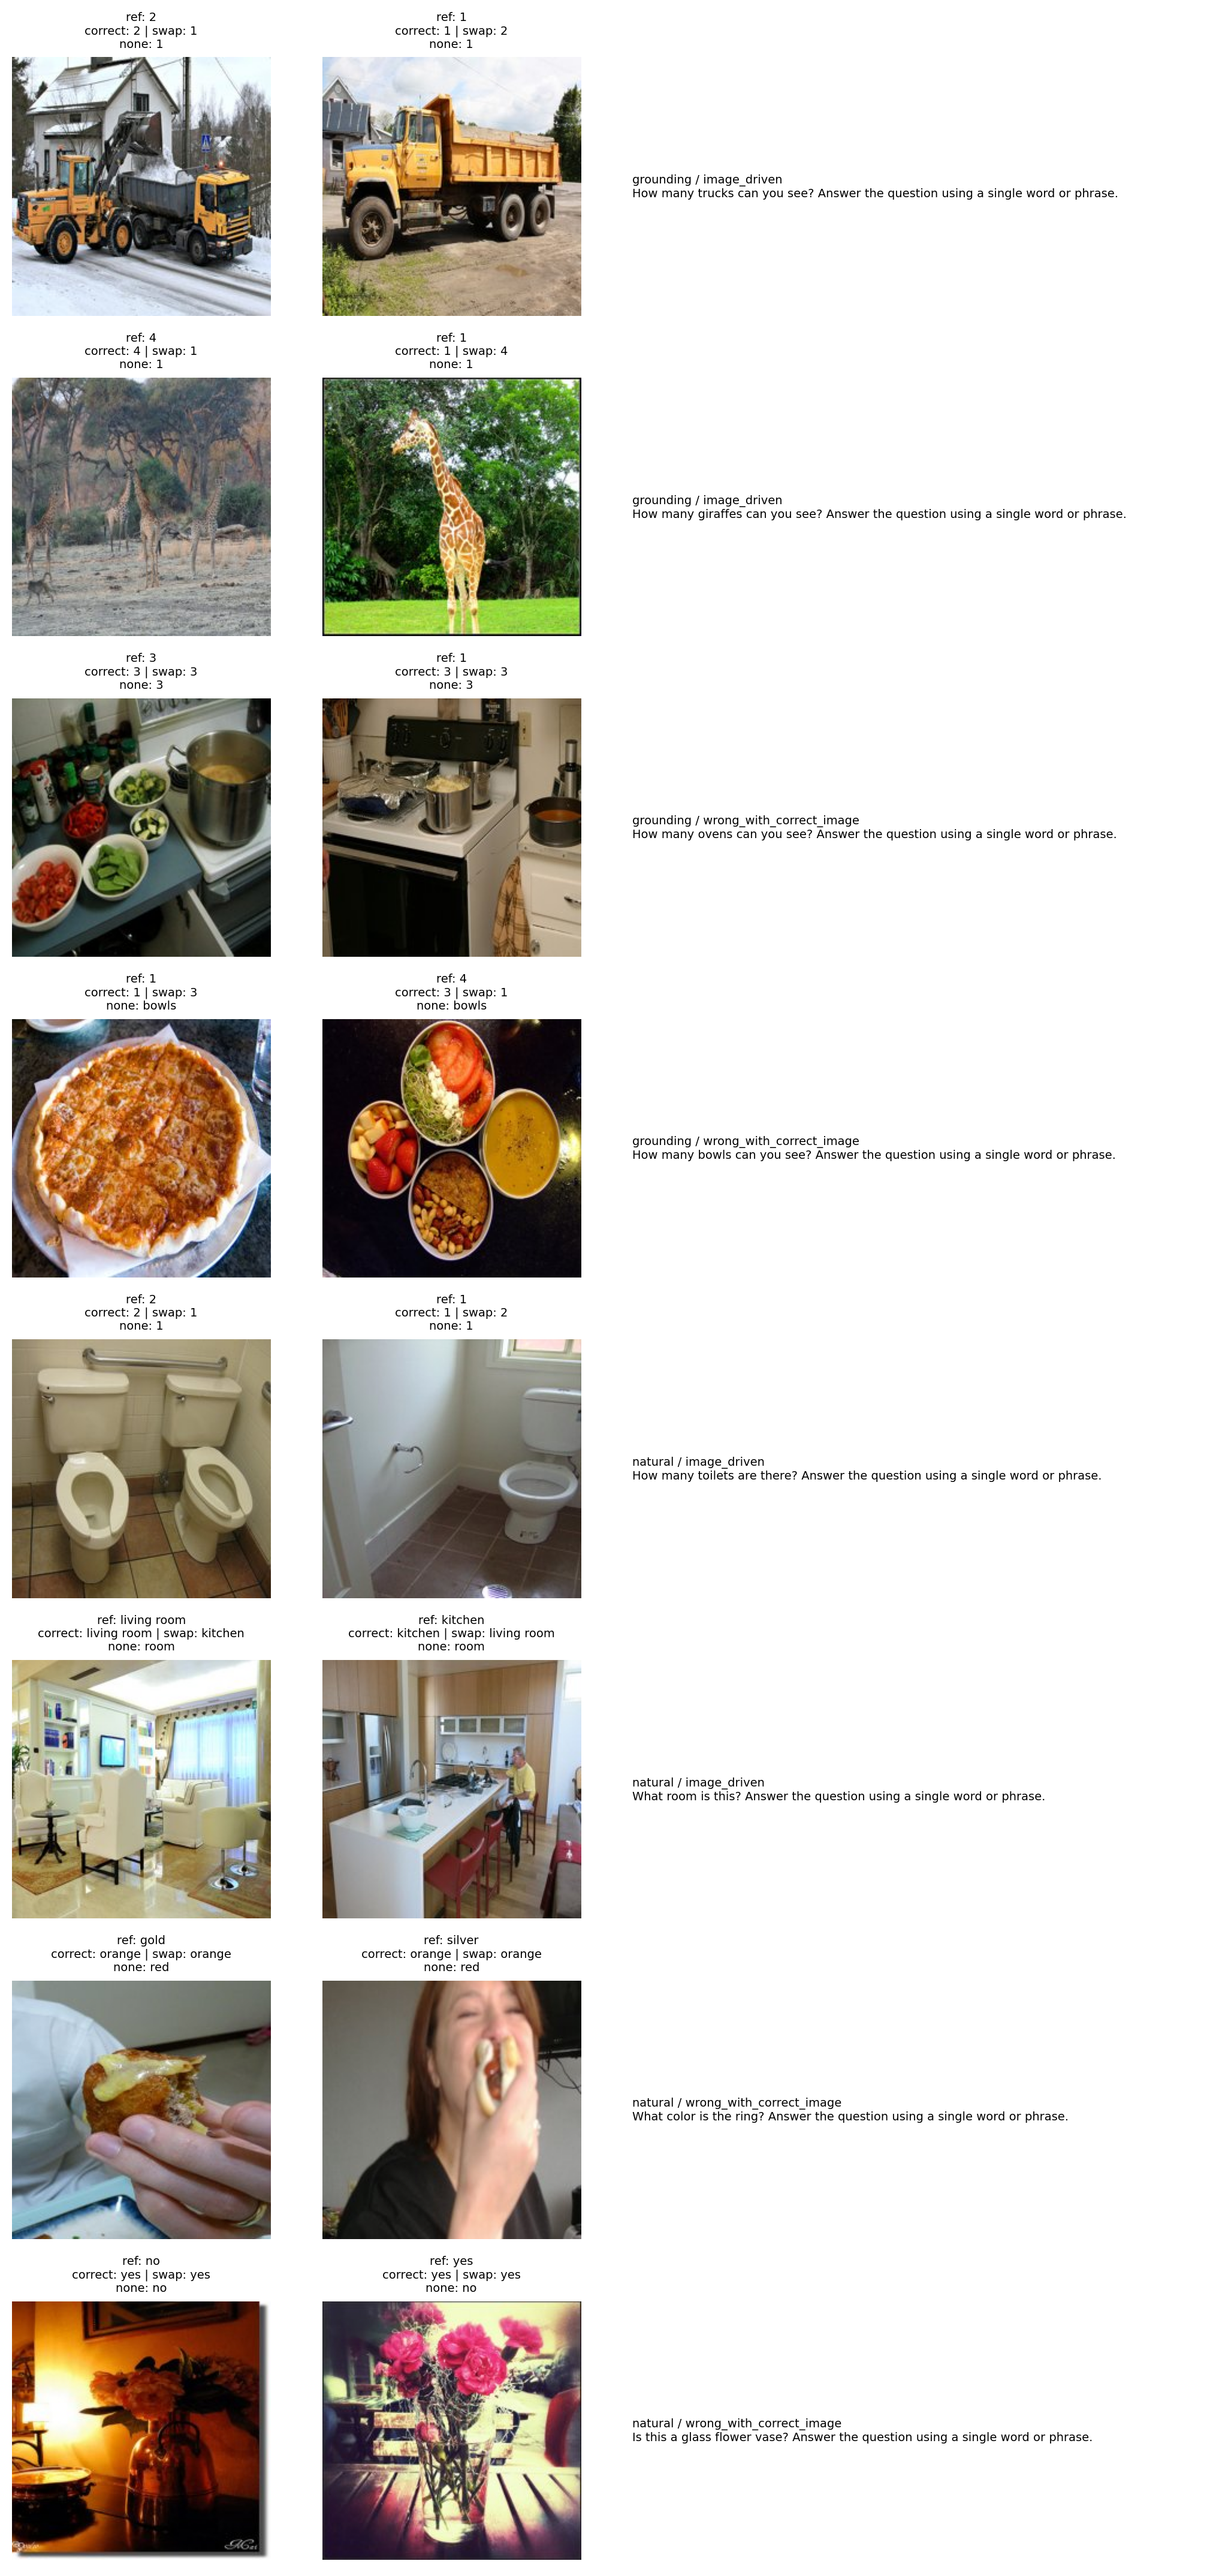

In [5]:
import pandas as pd
from IPython.display import Image, display

R = os.environ["PA3_RESULTS"] + "/task2"
for t in ["final_grounding_196", "final_natural_196", "advantages_196", "resources"]:
    display(pd.read_csv(f"{R}/tables/{t}.csv"))
for f in ["learning_curves_196", "final_accuracy_196", "qualitative_196"]:
    display(Image(f"{R}/figures/{f}.png"))